# Chosica TIF

In [1]:
import rasterio

ruta = "fabdem_chosica.tif"

with rasterio.open(ruta) as dem:
    datos = dem.read(1, masked=True)

    print("CRS:", dem.crs)
    print("Ancho:", dem.width)
    print("Alto:", dem.height)
    print("Resolución:", dem.res)
    print("Bandas:", dem.count)
    print("Elevación mínima:", datos.min())
    print("Elevación máxima:", datos.max())

CRS: EPSG:4326
Ancho: 1114
Alto: 929
Resolución: (0.00026949458523585647, 0.00026949458523585647)
Bandas: 1
Elevación mínima: 472.01
Elevación máxima: 3876.6


4326 son coordenadas geograficas.
- 1114 x 929 son en total 1.03 millones de celda.
- Por pixel son 30m.
- 1 banda -> elevacion
- 472m - 3877m
- El formato es EPSG:4326, una manera en este caso de medir las cuadriculas por medio de grados de latitud y longitud.
- La idea es convertir esto en metros.

In [2]:
from rasterio.warp import calculate_default_transform, reproject, Resampling

entrada = "fabdem_chosica.tif"
salida = "fabdem_chosica_utm18s.tif"

dst_crs = "EPSG:32718"

with rasterio.open(entrada) as src:
    # Simplemente calculamos la transformación y el tamaño de la nueva imagen
    transform, width, height = calculate_default_transform(
        src.crs,
        dst_crs,
        src.width,
        src.height,
        *src.bounds,
        resolution=30
    )

    # Reproyectamos la iamgen.
    perfil = src.profile.copy()

    perfil.update(
        crs=dst_crs,
        transform=transform,
        width=width,
        height=height
    )

    with rasterio.open(salida, "w", **perfil) as dst:

        reproject(
            source=rasterio.band(src, 1),
            destination=rasterio.band(dst, 1),
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=transform,
            dst_crs=dst_crs,
            resampling=Resampling.bilinear
        )

print("DEM reproyectado correctamente.")

DEM reproyectado correctamente.


In [3]:
ruta = "fabdem_chosica_utm18s.tif"

with rasterio.open(ruta) as dem:
    datos = dem.read(1, masked=True)

    print("CRS:", dem.crs)
    print("Ancho:", dem.width)
    print("Alto:", dem.height)
    print("Resolución:", dem.res)
    print("Bandas:", dem.count)
    print("Elevación mínima:", datos.min())
    print("Elevación máxima:", datos.max())
    print("Bounds:", dem.bounds)

CRS: EPSG:32718
Ancho: 1097
Alto: 930
Resolución: (30.0, 30.0)
Bandas: 1
Elevación mínima: 0.0
Elevación máxima: 3873.5322
Bounds: BoundingBox(left=298414.21871468564, bottom=8667214.515794426, right=331324.21871468564, top=8695114.515794426)


In [4]:
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling

entrada = "fabdem_chosica.tif"
salida = "fabdem_chosica_utm18s.tif"

dst_crs = "EPSG:32718"
nodata = -9999.0

with rasterio.open(entrada) as src:

    transform, width, height = calculate_default_transform(
        src.crs,
        dst_crs,
        src.width,
        src.height,
        *src.bounds,
        resolution=30
    )

    perfil = src.profile.copy()

    perfil.update(
        crs=dst_crs,
        transform=transform,
        width=width,
        height=height,
        nodata=nodata
    )

    with rasterio.open(salida, "w", **perfil) as dst:

        reproject(
            source=rasterio.band(src, 1),
            destination=rasterio.band(dst, 1),
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=transform,
            dst_crs=dst_crs,
            src_nodata=src.nodata,
            dst_nodata=nodata,
            resampling=Resampling.bilinear
        )

print("DEM reproyectado correctamente con NoData =", nodata)

DEM reproyectado correctamente con NoData = -9999.0


In [5]:
import rasterio

ruta = "fabdem_chosica_utm18s.tif"

with rasterio.open(ruta) as dem:
    datos = dem.read(1, masked=True)

    print("CRS:", dem.crs)
    print("Ancho:", dem.width)
    print("Alto:", dem.height)
    print("Resolución:", dem.res)
    print("Bandas:", dem.count)
    print("NoData:", dem.nodata)
    print("Elevación mínima:", datos.min())
    print("Elevación máxima:", datos.max())

CRS: EPSG:32718
Ancho: 1097
Alto: 930
Resolución: (30.0, 30.0)
Bandas: 1
NoData: -9999.0
Elevación mínima: 472.02066
Elevación máxima: 3873.5322


# Ahora lo preparamos para Hidrologia

In [6]:
import whitebox

wbt = whitebox.WhiteboxTools()

print("WhiteboxTools:", wbt.version())

WhiteboxTools: WhiteboxTools v2.4.0 (c) Dr. John Lindsay 2017-2023

WhiteboxTools is an advanced geospatial data analysis platform developed at
the University of Guelph's Geomorphometry and Hydrogeomatics Research 
Group (GHRG). See www.whiteboxgeo.com for more details.



Procederemos con preparar el marco para hidrologia.
- Debemos imaginar que el DEM cuenta con una pequeña depresión.
- A veces, cuentan con un hueco artificial.
- Fill lo que hace es rellenar ese fondo, para que no quede plano.
- Breach es abrir una salida, en vez de levantar todo el terreno, intenta abrir un pequeno canal.
- Esto pq DEM a veces cuenta con pequenas depresiones por errores de medicoin, etc.


In [12]:
import os

print(os.path.exists("fabdem_chosica_utm18s.tif"))

True


In [14]:
import os

dem_entrada = os.path.abspath("fabdem_chosica_utm18s.tif")
dem_breached = os.path.abspath("fabdem_chosica_hydro.tif")

print("Entrada:", dem_entrada)
print("Existe:", os.path.exists(dem_entrada))

Entrada: c:\Users\Camil\Desktop\CV u otras vainas\Hackaton SAS\fabdem_chosica_utm18s.tif
Existe: True


In [15]:
wbt.breach_depressions(
    dem_entrada,
    dem_breached
)

.\whitebox_tools.exe --run="BreachDepressions" --dem='c:\Users\Camil\Desktop\CV u otras vainas\Hackaton SAS\fabdem_chosica_utm18s.tif' --output='c:\Users\Camil\Desktop\CV u otras vainas\Hackaton SAS\fabdem_chosica_hydro.tif' -v --compress_rasters=False

********************************
* Welcome to BreachDepressions *
* Powered by WhiteboxTools     *
* www.whiteboxgeo.com          *
********************************
Reading data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
P

0

# Direccion de Flujo

Ahora vamosa  veriricar por pixel, saber hacia cual de sus vecinos bajaria el agua.

In [16]:
# Usaremos D8, son los 8 vecinos por pixel.
dem_hydro = os.path.abspath("fabdem_chosica_hydro.tif")
flow_dir = os.path.abspath("flow_direction_d8.tif")

wbt.d8_pointer(
    dem_hydro,
    flow_dir
)

print("Dirección de flujo calculada.")

.\whitebox_tools.exe --run="D8Pointer" --dem='c:\Users\Camil\Desktop\CV u otras vainas\Hackaton SAS\fabdem_chosica_hydro.tif' --output='c:\Users\Camil\Desktop\CV u otras vainas\Hackaton SAS\flow_direction_d8.tif' -v --compress_rasters=False

****************************
* Welcome to D8Pointer     *
* Powered by WhiteboxTools *
* www.whiteboxgeo.com      *
****************************
Reading data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
Progress: 41%
Progress: 42%
Progr

Ahora el formato es por medio de flechas.

In [17]:
flow_dir = os.path.abspath("flow_direction_d8.tif")
flow_accum = os.path.abspath("flow_accumulation_d8.tif")

wbt.d8_flow_accumulation(
    flow_dir,
    flow_accum,
    pntr=True
)

print("Acumulación de flujo calculada.")

.\whitebox_tools.exe --run="D8FlowAccumulation" --input='c:\Users\Camil\Desktop\CV u otras vainas\Hackaton SAS\flow_direction_d8.tif' --output='c:\Users\Camil\Desktop\CV u otras vainas\Hackaton SAS\flow_accumulation_d8.tif' --out_type=cells --pntr -v --compress_rasters=False

*********************************
* Welcome to D8FlowAccumulation *
* Powered by WhiteboxTools      *
* www.whiteboxgeo.com           *
*********************************
Reading data...
Flow directions: 0%
Flow directions: 1%
Flow directions: 2%
Flow directions: 3%
Flow directions: 4%
Flow directions: 5%
Flow directions: 6%
Flow directions: 7%
Flow directions: 8%
Flow directions: 9%
Flow directions: 10%
Flow directions: 11%
Flow directions: 12%
Flow directions: 13%
Flow directions: 14%
Flow directions: 15%
Flow directions: 16%
Flow directions: 17%
Flow directions: 18%
Flow directions: 19%
Flow directions: 20%
Flow directions: 21%
Flow directions: 22%
Flow directions: 23%
Flow directions: 24%
Flow directions: 25%
F

In [20]:
import numpy as np
import rasterio

ruta = "flow_accumulation_d8.tif"

with rasterio.open(ruta) as src:
    acumulacion = src.read(1, masked=True)

    print("CRS:", src.crs)
    print("Tamaño:", src.width, "x", src.height)
    print("Resolución:", src.res)
    print("Mínimo:", acumulacion.min())
    print("Máximo:", acumulacion.max())

    percentiles = np.percentile(
        acumulacion.compressed(),
        [50, 75, 90, 95, 99]
    )

    print("Percentiles 50, 75, 90, 95, 99:")
    print(percentiles)

CRS: EPSG:32718
Tamaño: 1097 x 930
Resolución: (30.0, 30.0)
Mínimo: 1.0
Máximo: 485791.0
Percentiles 50, 75, 90, 95, 99:
[3.000e+00 8.000e+00 3.400e+01 1.350e+02 3.718e+03]


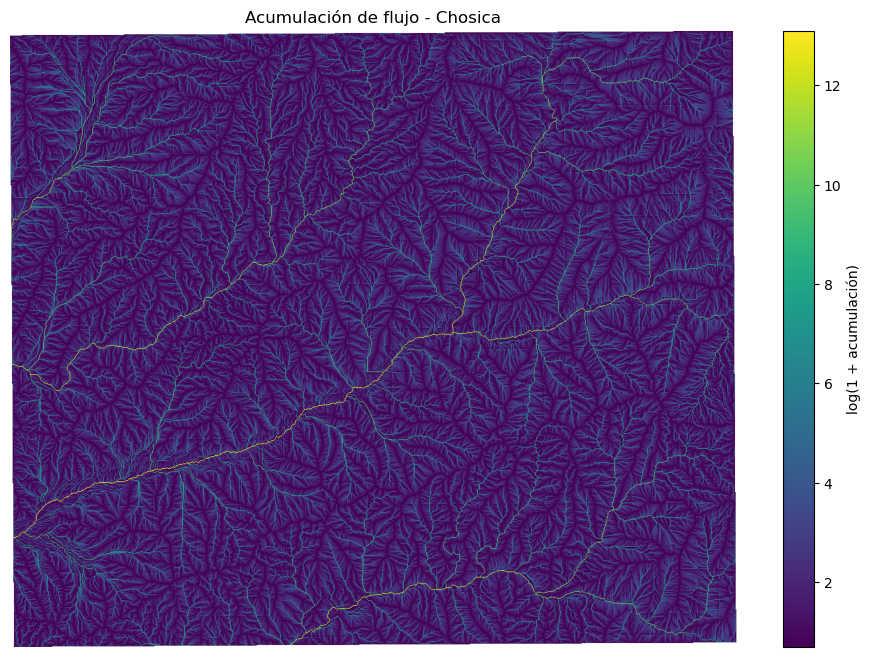

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import rasterio

with rasterio.open("flow_accumulation_d8.tif") as src:
    acumulacion = src.read(1, masked=True)

# Transformación solo para visualizar mejor los valores
acum_log = np.ma.log(1 + acumulacion)

plt.figure(figsize=(12, 8))

plt.imshow(
    acum_log,
    cmap="viridis"
)

plt.colorbar(
    label="log(1 + acumulación)"
)

plt.title("Acumulación de flujo - Chosica")
plt.axis("off")
plt.show()

Ahora consideraremos Cauce a tod opixel que recibe flujode a lmenos N celdas aguas arriba.

In [22]:
import os

flow_accum = os.path.abspath("flow_accumulation_d8.tif")
streams_1000 = os.path.abspath("streams_threshold_1000.tif")

wbt.extract_streams(
    flow_accum,
    streams_1000,
    threshold=1000
)

print("Red de drenaje candidata generada.")

.\whitebox_tools.exe --run="ExtractStreams" --flow_accum='c:\Users\Camil\Desktop\CV u otras vainas\Hackaton SAS\flow_accumulation_d8.tif' --output='c:\Users\Camil\Desktop\CV u otras vainas\Hackaton SAS\streams_threshold_1000.tif' --threshold='1000' -v --compress_rasters=False

*****************************
* Welcome to ExtractStreams *
* Powered by WhiteboxTools  *
* www.whiteboxgeo.com       *
*****************************
Reading data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progre

Valores presentes: {np.float32(-32768.0), np.float32(1.0)}


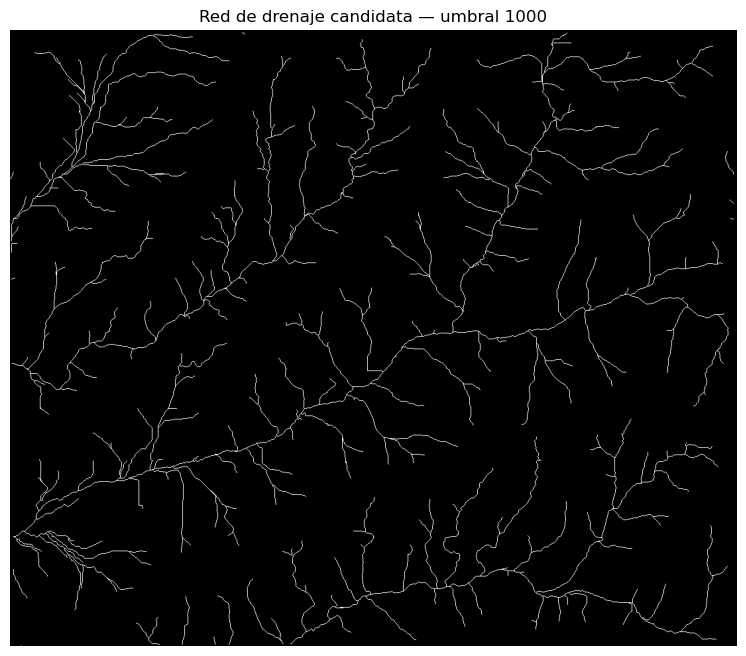

In [23]:
import matplotlib.pyplot as plt
import rasterio

with rasterio.open("streams_threshold_1000.tif") as src:
    streams = src.read(1)

print("Valores presentes:", set(streams.flatten()))

plt.figure(figsize=(12, 8))
plt.imshow(streams, cmap="gray")
plt.title("Red de drenaje candidata — umbral 1000")
plt.axis("off")
plt.show()

In [24]:
import os

flow_accum = os.path.abspath("flow_accumulation_d8.tif")

umbrales = [100, 500, 1000, 2500, 5000, 10000]

for umbral in umbrales:
    salida = os.path.abspath(f"streams_{umbral}.tif")

    wbt.extract_streams(
        flow_accum,
        salida,
        threshold=umbral
    )

print("Todas las redes candidatas fueron generadas.")

.\whitebox_tools.exe --run="ExtractStreams" --flow_accum='c:\Users\Camil\Desktop\CV u otras vainas\Hackaton SAS\flow_accumulation_d8.tif' --output='c:\Users\Camil\Desktop\CV u otras vainas\Hackaton SAS\streams_100.tif' --threshold='100' -v --compress_rasters=False

*****************************
* Welcome to ExtractStreams *
* Powered by WhiteboxTools  *
* www.whiteboxgeo.com       *
*****************************
Reading data...
Progress: 0%
Progress: 1%
Progress: 2%
Progress: 3%
Progress: 4%
Progress: 5%
Progress: 6%
Progress: 7%
Progress: 8%
Progress: 9%
Progress: 10%
Progress: 11%
Progress: 12%
Progress: 13%
Progress: 14%
Progress: 15%
Progress: 16%
Progress: 17%
Progress: 18%
Progress: 19%
Progress: 20%
Progress: 21%
Progress: 22%
Progress: 23%
Progress: 24%
Progress: 25%
Progress: 26%
Progress: 27%
Progress: 28%
Progress: 29%
Progress: 30%
Progress: 31%
Progress: 32%
Progress: 33%
Progress: 34%
Progress: 35%
Progress: 36%
Progress: 37%
Progress: 38%
Progress: 39%
Progress: 40%
Prog

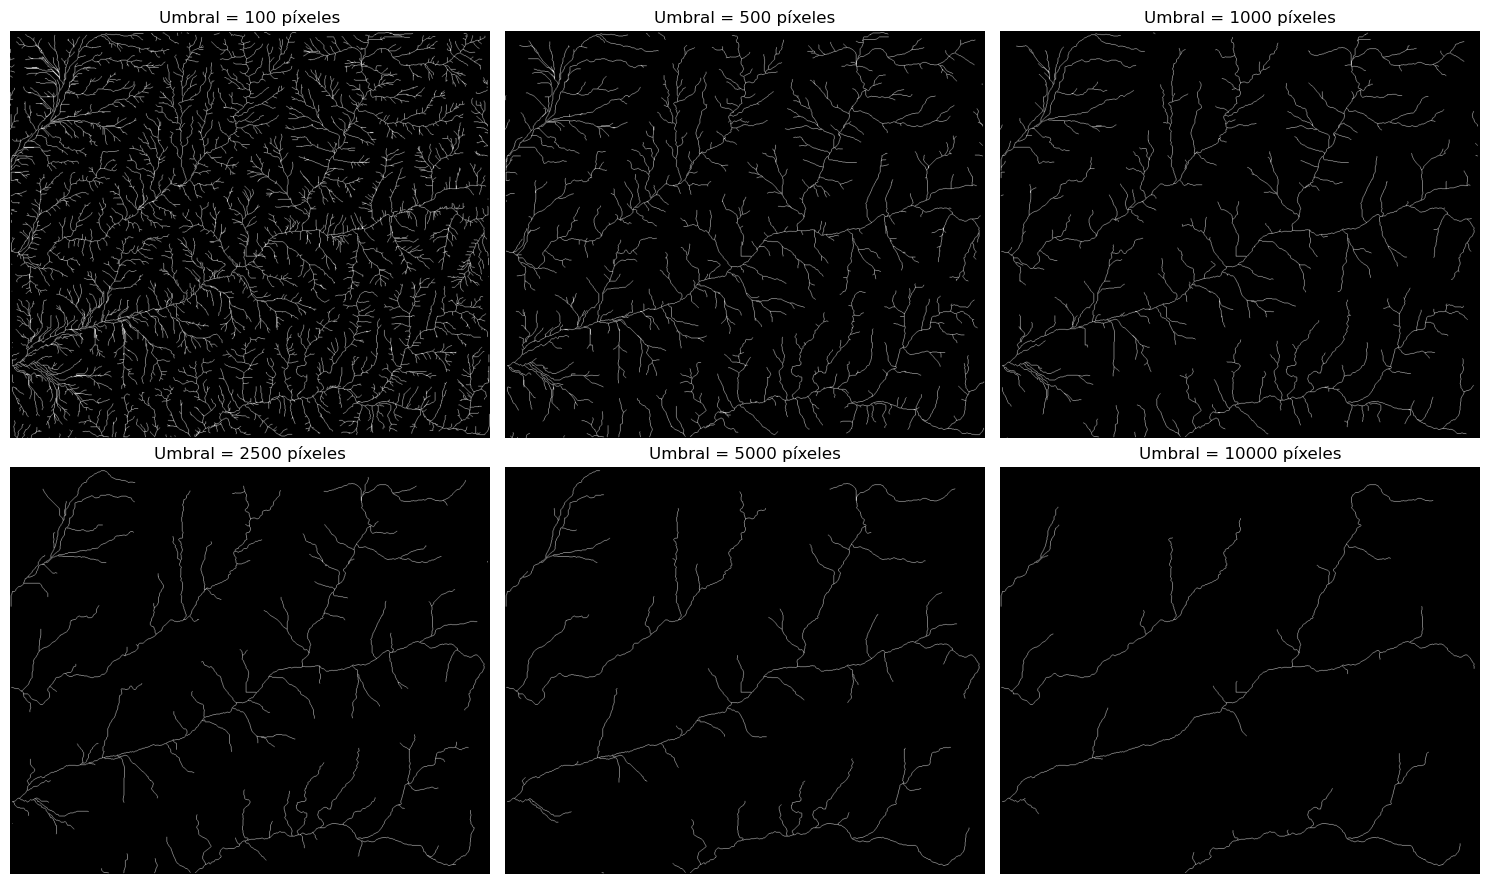

In [25]:
import matplotlib.pyplot as plt
import rasterio
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, umbral in zip(axes.flat, umbrales):

    with rasterio.open(f"streams_{umbral}.tif") as src:
        datos = src.read(1)

    # 1 = cauce, cualquier otra cosa = fondo
    red = (datos == 1).astype(np.uint8)

    ax.imshow(red, cmap="gray")
    ax.set_title(f"Umbral = {umbral} píxeles")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [29]:
import pandas as pd
df = pd.read_csv("terreno/pendientes_ubicar.csv")
df.head(30)

,nombre,nombres_catalogo,n_eventos,eventos,sectores,km_carretera,distritos,notas_catalogo,nota_referencia,salida_lat,salida_lon
0,Chacrasana,Chacrasana,8,"EV004, EV019, EV058, EV092, EV103, EV115, EV12...",Chacrasana | Av. Mirtha Alvarado / Carretera C...,km 27 | km 27.8,Lurigancho-Chosica,"EV019: 'las quebradas de Chacrasana, Pedregal,...",no está en ANA,NaN,NaN
1,Yanacoto,Yanacoto,6,"EV014, EV051, EV067, EV097, EV119, EV123",Yanacoto | Carretera Central km 25-27,km 25-27,Lurigancho-Chosica,EV014: El Comercio: lluvias 'activaron las que...,"Yanacoto: quebrada aparte, pendiente de ubicar...",NaN,NaN
2,Libertad,Libertad,4,"EV032, EV049, EV078, EV095","jirón Colombia, calle Santa María; Carretera C...",NaN,Lurigancho-Chosica,EV078: Domingo. Lluvia: 'fuertes lluvias duran...,no está en ANA,NaN,NaN
3,Mariscal Castilla,Mariscal Castilla,4,"EV008, EV033, EV087, EV130",Mariscal Castilla,NaN,Lurigancho-Chosica,"EV087: Texto: 'El 14 de marzo del 2023, a las ...",no está en ANA,NaN,NaN
4,Rosario,Rosario,3,"EV010, EV080, EV126","jirón Colombia, calle Santa María; Carretera C...",NaN,Lurigancho-Chosica,EV010: Hora tomada de Correo 563875 || EV080: ...,no está en ANA,NaN,NaN
5,Santo Domingo (Chosica),Santo Domingo,3,"EV013, EV074, EV081",AAHH Cañaverales y Burga Saldaña (zona La Cant...,NaN,Lurigancho-Chosica,EV013: Hora tomada de Correo 563875 || EV074: ...,Santo Domingo: no está en ANA: la 'Quebrada Sa...,NaN,NaN
6,El Vallecito,El Vallecito,2,"EV068, EV083",Asociación Las Lomas; Carretera Central km 20 ...,km 20,Lurigancho-Chosica,EV068: La República: 'aproximadamente a las 2:...,no está en ANA,NaN,NaN
7,Inca Kola,Inca Kola,2,"EV024, EV053",Paradero Inka Kola,NaN,Lurigancho-Chosica,EV024: Nota publicada 23/03/2015 4:32 p.m. (ev...,Inca Kola: sector/barrio; quebrada no identifi...,NaN,NaN
8,Tarazona,Tarazona,2,"EV082, EV111","jirón Colombia, calle Santa María; Carretera C...",km 32,Lurigancho-Chosica,EV082: Domingo. Lluvia: 'fuertes lluvias duran...,no está en ANA,NaN,NaN
9,Alto Perú,Alto Perú,1,EV085,AAHH Alto Perú,NaN,Lurigancho-Chosica,EV085: Texto: 'Las intensas lluvias que se viv...,Alto Perú: sector/barrio; quebrada no identifi...,NaN,NaN
